In [1]:
import pandas as pd
import numpy as np
import tqdm
from sklearn.model_selection import train_test_split
from datasets import Dataset, DatasetDict
from huggingface_hub import login

import torch
from torch import nn
from sklearn.utils.class_weight import compute_class_weight

import ast
import re

# Silence transformers' informational/warning logs (e.g. legacy LayerNorm
# gamma/beta key-name notices when Trainer reloads the best checkpoint).
# Doesn't affect training/evaluation, only console noise.
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()

In [2]:
df = pd.read_csv("/kaggle/input/datasets/audreytheodoraphang/data-thesis/data_thesis.csv")

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26379 entries, 0 to 26378
Data columns (total 15 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   Unnamed: 0                     26379 non-null  int64 
 1   text_id                        26379 non-null  object
 2   annotators_id                  26379 non-null  object
 3   text                           26379 non-null  object
 4   topic                          26379 non-null  object
 5   is_noise_or_spam_text          26379 non-null  int64 
 6   toxicity                       26379 non-null  int64 
 7   polarized                      26379 non-null  int64 
 8   profanity_obscenity            26379 non-null  int64 
 9   threat_incitement_to_violence  26379 non-null  int64 
 10  insults                        26379 non-null  int64 
 11  identity_attack                26379 non-null  int64 
 12  sexually_explicit              26379 non-null  int64 
 13  c

In [4]:
df.head()

,Unnamed: 0,text_id,annotators_id,text,topic,is_noise_or_spam_text,toxicity,polarized,profanity_obscenity,threat_incitement_to_violence,insults,identity_attack,sexually_explicit,cleaned_text,processed_text
0,0,2026-01-01 00:00:00,"['7', '15']",Wajah Jurnalis Dibalut Perban Saat Melaporkan ...,UNKNOWN,0,0,0,0,0,0,0,0,Wajah jurnalis dibalut perban saat melaporkan ...,wajah jurnalis dibalut perban saat melaporkan ...
1,1,2026-01-10 00:00:00,"['7', '15']",Elektabilitas Paslon 02 sebentar lagi terjun b...,Disabilitas,0,0,1,0,0,0,0,0,Elektabilitas pasangan calon 02 sebentar lagi ...,elektabilitas pasangan calon sebentar lagi ter...
2,2,1-1001,"['10', '18']","Kristen, Hindu, Islam dapat perlakuan istimewa...",Kristen,0,0,1,0,0,0,0,0,"Kristen, Hindu, Islam dapat perlakuan istimewa...","kristen, hindu, islam dapat perlakuan istimewa..."
3,3,1-1004,"['10', '18']","Masyarakat Kristen, Hindu, Budha, dan etnis Ti...","Kristen, Tionghoa",0,0,0,0,0,0,0,0,"Masyarakat Kristen, Hindu, Buddha, dan etnis T...","masyarakat kristen, hindu, buddha, dan etnis t..."
4,4,1-1005,"['10', '18']",Cina Mengirimkan Satelit Penginderaan Jauh Bar...,Tionghoa,0,0,0,0,0,0,0,0,Cina mengirimkan satelit penginderaan jauh bar...,cina mengirimkan satelit penginderaan jauh bar...


In [5]:
def transform_datetime_id(text_id_str):
    # Regex to match the datetime pattern like 'YYYY-MM-DD HH:MM:SS'
    match = re.match(r'(\d+)-(\d{2})-(\d{2}) \d{2}:\d{2}:\d{2}', str(text_id_str))
    if match:
        year_part = match.group(1)
        month_part = int(match.group(2))
        day_part = int(match.group(3))

        if year_part == '2026':
            # For year 2026, format as month-day (e.g., '1-1')
            return f"{month_part}-{day_part}"
        else:
            # For other years, format as month-original_year (e.g., '2-8783')
            return f"{month_part}-{year_part}"
    else:
        return text_id_str  # Return original if pattern doesn't match

# Apply this transformation to the 'text_id' column of your DataFrame
df['text_id'] = df['text_id'].apply(transform_datetime_id)

In [6]:
cols = [
'is_noise_or_spam_text',
'toxicity',
'polarized',
'profanity_obscenity',
'threat_incitement_to_violence',
'insults',
'identity_attack',
'sexually_explicit'
]

for col in cols:
    df[col] = df[col].apply(lambda x: ast.literal_eval(x) if isinstance(x,str) else x)

In [7]:
df_main = df.copy()

In [8]:
print(df_main['is_noise_or_spam_text'].iloc[0])
print(type(df_main['is_noise_or_spam_text'].iloc[0]))

print(df_main['polarized'].iloc[0])
print(type(df_main['polarized'].iloc[0]))

print(df_main['profanity_obscenity'].iloc[0])
print(type(df_main['profanity_obscenity'].iloc[0]))

print(df_main['insults'].iloc[0])
print(type(df_main['insults'].iloc[0]))

print(df_main['sexually_explicit'].iloc[0])
print(type(df_main['sexually_explicit'].iloc[0]))

print(df_main['identity_attack'].iloc[0])
print(type(df_main['identity_attack'].iloc[0]))

print(df_main['toxicity'].iloc[0])
print(type(df_main['toxicity'].iloc[0]))

0
<class 'numpy.int64'>
0
<class 'numpy.int64'>
0
<class 'numpy.int64'>
0
<class 'numpy.int64'>
0
<class 'numpy.int64'>
0
<class 'numpy.int64'>
0
<class 'numpy.int64'>


In [9]:
df_main = df_main[df_main['is_noise_or_spam_text'] == 0]

In [10]:
df_main.isnull().sum()

Unnamed: 0                       0
text_id                          0
annotators_id                    0
text                             0
topic                            0
is_noise_or_spam_text            0
toxicity                         0
polarized                        0
profanity_obscenity              0
threat_incitement_to_violence    0
insults                          0
identity_attack                  0
sexually_explicit                0
cleaned_text                     0
processed_text                   0
dtype: int64

In [11]:
slang_dict = {
    "gk": "tidak",
    "ga": "tidak",
    "nggak": "tidak",
    "yg": "yang",
    "lu": "kamu",
    "loe": "kamu",
    "gw": "saya",
    "gue": "saya",
    "bgt": "banget",
    "dgn": "dengan",
    "krn": "karena",
    "aja": "saja",
    "trs": "terus"
}

In [12]:
import re

def normalize_slang(text, slang_dict):
    words = text.split()
    return " ".join([slang_dict.get(w.lower(), w) for w in words])

def preprocess_text(text, slang_dict, lowercase=True):
    if not isinstance(text, str):
        return ""

    # 1. remove username (@user)
    text = re.sub(r'@\w+', '', text)

    # 2. remove URL
    text = re.sub(r'http\S+|www\.\S+', '', text)

    # 3. remove numbers
    text = re.sub(r'\d+', '', text)

    # 4. remove unwanted symbols (keep .,!?)
    text = re.sub(r'[^\w\s.,!?]', '', text)

    # 5. normalize slang
    text = normalize_slang(text, slang_dict)

    # 6. normalize repeated chars (contoh: anjiiing -> anjiing)
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)

    # 7. lowercase (optional)
    if lowercase:
        text = text.lower()

    # 8. remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text

In [13]:
from tqdm import tqdm
tqdm.pandas()

df_main["processed_text"] = (
    df_main["cleaned_text"]
    .fillna("")
    .astype(str)
    .progress_apply(
        lambda x: preprocess_text(x, slang_dict)
    )
)

100%|██████████| 26379/26379 [00:01<00:00, 18764.37it/s]


In [14]:
df_main['toxicity'].value_counts()

toxicity
0    23980
1     2399
Name: count, dtype: int64

In [15]:
df_main['profanity_obscenity'].value_counts()

profanity_obscenity
0    26018
1      361
Name: count, dtype: int64

In [16]:
df_main['insults'].value_counts()

insults
0    25315
1     1064
Name: count, dtype: int64

In [17]:
df_main['identity_attack'].value_counts()

identity_attack
0    25365
1     1014
Name: count, dtype: int64

# Stage 1

In [18]:
x = df_main['processed_text']
y = df_main['toxicity']

In [19]:
# Split into train / validation / test (70% / 20% / 10%). The test split uses the same
# test_size=0.2, random_state=42 as before, so it is the exact same held-out data as
# earlier runs -- only the remaining 80% is further split into train/validation instead
# of all of it being used as "train". Validation is what checkpoint selection
# (load_best_model_at_end) and decision-threshold tuning are done against; test stays
# completely untouched until the final, one-shot evaluation at the end, so the reported
# numbers there aren't inflated by tuning on the same data being scored.
x_train_full, x_test, y_train_full, y_test = train_test_split(
    x, y, test_size=0.2, stratify=y, random_state=42
)
x_train, x_val, y_train, y_val = train_test_split(
    x_train_full, y_train_full, test_size=0.125, stratify=y_train_full, random_state=42
)

print("Stage 1 split sizes:", {"train": len(x_train), "val": len(x_val), "test": len(x_test)})

Stage 1 split sizes: {'train': 18465, 'val': 2638, 'test': 5276}


In [20]:
# Handle imbalance for Stage 1 (toxicity: binary) via class weights, used by a weighted
# CrossEntropyLoss below. Computed from the train split only.
class_weights_s1 = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)
class_weights_s1 = torch.tensor(class_weights_s1, dtype=torch.float)
print("Stage 1 class weights (class 0, class 1):", class_weights_s1)

Stage 1 class weights (class 0, class 1): tensor([0.5500, 5.4988])


In [21]:
train_df = pd.DataFrame({"processed_text": x_train, "label": y_train})
val_df = pd.DataFrame({"processed_text": x_val, "label": y_val})
test_df = pd.DataFrame({"processed_text": x_test, "label": y_test})

dataset = DatasetDict({
    "train": Dataset.from_pandas(train_df),
    "validation": Dataset.from_pandas(val_df),
    "test": Dataset.from_pandas(test_df)
})

In [22]:
from transformers import AutoTokenizer, Trainer, TrainingArguments, AutoModelForSequenceClassification
tokenizer = AutoTokenizer.from_pretrained("indolem/indobertweet-base-uncased")

config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

In [23]:
def tokenize(batch):
    return tokenizer(
        batch["processed_text"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

In [24]:
tokenized_datasets_1 = dataset.map(tokenize, batched=True)

tokenized_datasets_1 = tokenized_datasets_1.remove_columns(["processed_text"])
tokenized_datasets_1 = tokenized_datasets_1.rename_column("label", "labels")
tokenized_datasets_1.set_format("torch")

train_dataset_1 = tokenized_datasets_1["train"]
val_dataset_1 = tokenized_datasets_1["validation"]
test_dataset_1 = tokenized_datasets_1["test"]

Map:   0%|          | 0/18465 [00:00<?, ? examples/s]

Map:   0%|          | 0/2638 [00:00<?, ? examples/s]

Map:   0%|          | 0/5276 [00:00<?, ? examples/s]

In [25]:
from transformers import AutoModelForSequenceClassification

model_s1 = AutoModelForSequenceClassification.from_pretrained(
    "indolem/indobertweet-base-uncased",
    num_labels=2
)

pytorch_model.bin:   0%|          | 0.00/445M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

In [26]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, classification_report, auc, roc_curve
def compute_metrics_s1(eval_pred):
    logits, labels = eval_pred
    preds = logits.argmax(axis=1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "f1": f1_score(labels, preds),
        "recall": recall_score(labels, preds),
        "precision": precision_score(labels, preds),
        "roc_auc": auc(roc_curve(labels, preds)[0], roc_curve(labels, preds)[1])
    }

model.safetensors:   0%|          | 0.00/445M [00:00<?, ?B/s]

In [27]:
# Trainer that applies class weights to CrossEntropyLoss, used to handle label
# imbalance in Stage 1.
class WeightedTrainerSingleLabel(Trainer):
    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        weight = self.class_weights.to(logits.device) if self.class_weights is not None else None
        loss_fct = nn.CrossEntropyLoss(weight=weight)
        # logits.size(-1) instead of model.config.num_labels: stays correct even if
        # Trainer wraps the model in nn.DataParallel (which doesn't expose .config).
        loss = loss_fct(logits.view(-1, logits.size(-1)), labels.view(-1))
        return (loss, outputs) if return_outputs else loss

In [ ]:
# metric_for_best_model="f1" (with greater_is_better=True) instead of the default
# eval_loss: on an imbalanced binary task, the checkpoint with the lowest eval_loss is
# not necessarily the one with the best toxic-class F1 -- eval_loss can keep dropping
# by getting more confident on the easy majority class while F1 on the minority class
# stagnates or regresses. eval_dataset is the VALIDATION split (not test), so checkpoint
# selection never looks at the test set.
#
# weight_decay=0.01 regularizes the weights (via AdamW) to reduce overfitting.
# EarlyStoppingCallback stops training once eval_f1 hasn't improved for
# early_stopping_patience consecutive eval rounds -- the loss plot below showed
# val_loss bottoming out around epoch 1-2 then climbing while train_loss kept
# dropping (overfitting), so this stops training around that point automatically
# instead of always running the full num_train_epochs.
from transformers import EarlyStoppingCallback

args_s1 = TrainingArguments(
    output_dir="./baseline_s1",
    num_train_epochs=5,
    logging_steps=1,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    learning_rate = 1e-5,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,
    remove_unused_columns=False,
    disable_tqdm=False
)

trainer_s1 = WeightedTrainerSingleLabel(
    model=model_s1,
    args=args_s1,
    train_dataset=train_dataset_1,
    eval_dataset=val_dataset_1,
    compute_metrics=compute_metrics_s1,
    class_weights=class_weights_s1,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)]
)

In [29]:

import sys
import datasets

# Matikan torchvision di runtime
if "torchvision" in sys.modules:
    del sys.modules["torchvision"]

# Paksa datasets menganggap torchvision tidak tersedia
datasets.config.TORCHVISION_AVAILABLE = False

print("TORCHVISION_AVAILABLE:", datasets.config.TORCHVISION_AVAILABLE)
print("torchvision loaded:", "torchvision" in sys.modules)

TORCHVISION_AVAILABLE: False
torchvision loaded: False


In [30]:
print("=== TRAINER ===")
print("label_names:", trainer_s1.label_names)
print("remove_unused_columns:", trainer_s1.args.remove_unused_columns)

print("\n=== DATASET ===")
print(trainer_s1.train_dataset.column_names)

print("\n=== SAMPLE ===")
sample = trainer_s1.train_dataset[0]
print(sample.keys())
print("labels:", sample.get("labels"))

print("\n=== MODEL ===")
print(type(trainer_s1.model))

=== TRAINER ===
label_names: ['labels']
remove_unused_columns: False

=== DATASET ===
['labels', '__index_level_0__', 'input_ids', 'token_type_ids', 'attention_mask']

=== SAMPLE ===
dict_keys(['labels', '__index_level_0__', 'input_ids', 'token_type_ids', 'attention_mask'])
labels: tensor(0)

=== MODEL ===
<class 'transformers.models.bert.modeling_bert.BertForSequenceClassification'>


In [31]:
# Run this line first, then restart the runtime, and finally re-execute all cells up to this point.
# !pip install --upgrade --force-reinstall torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121

trainer_s1.train()

Epoch,Training Loss,Validation Loss,Accuracy,F1,Recall,Precision,Roc Auc
1,0.006307,0.473378,0.848749,0.461538,0.712500,0.341317,0.787443
2,0.009248,0.558536,0.886277,0.489796,0.600000,0.413793,0.757465
3,0.006706,0.589102,0.874905,0.495413,0.675000,0.391304,0.784956
4,0.034146,0.896846,0.905610,0.490798,0.500000,0.481928,0.723103
5,0.005513,1.005018,0.904852,0.480331,0.483333,0.477366,0.715186


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=5775, training_loss=0.3950602231036219, metrics={'train_runtime': 1726.2572, 'train_samples_per_second': 53.483, 'train_steps_per_second': 3.345, 'total_flos': 6072932046528000.0, 'train_loss': 0.3950602231036219, 'epoch': 5.0})

In [ ]:
import json, os

# Persist the best checkpoint (already loaded into trainer_s1.model because
# load_best_model_at_end=True) + tokenizer, and the full training log, so both can be
# reloaded later without rerunning trainer_s1.train().
SAVE_DIR_S1 = "./best_model_s1"
os.makedirs(SAVE_DIR_S1, exist_ok=True)

trainer_s1.save_model(SAVE_DIR_S1)
tokenizer.save_pretrained(SAVE_DIR_S1)

with open(os.path.join(SAVE_DIR_S1, "log_history.json"), "w") as f:
    json.dump(trainer_s1.state.log_history, f)

print(f"Saved best model + tokenizer + log_history to {SAVE_DIR_S1}")

# --- To reload later (e.g. new session, without retraining) ---
# model_s1 = AutoModelForSequenceClassification.from_pretrained(SAVE_DIR_S1)
# tokenizer = AutoTokenizer.from_pretrained(SAVE_DIR_S1)
# with open(os.path.join(SAVE_DIR_S1, "log_history.json")) as f:
#     history = json.load(f)

In [33]:
history = trainer_s1.state.log_history
train_loss = [x['loss'] for x in history if 'loss' in x]
val_loss = [x['eval_loss'] for x in history if 'eval_loss' in x]
epochs = [x['epoch'] for x in history if 'eval_loss' in x]

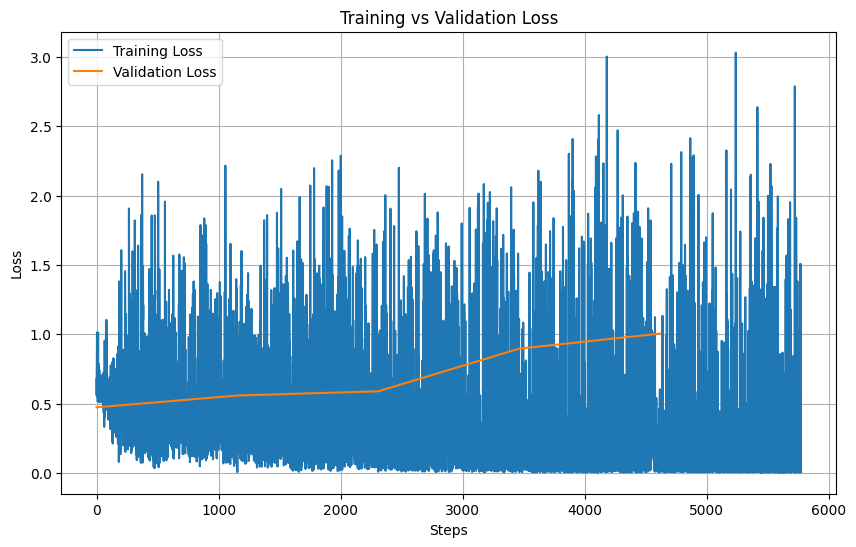

In [34]:
from matplotlib import pyplot as plt
plt.figure(figsize=(10, 6))
plt.plot(train_loss, label='Training Loss')
plt.plot(range(0, len(train_loss), len(train_loss)//len(val_loss)), val_loss, label='Validation Loss')
plt.title('Training vs Validation Loss')
plt.xlabel('Steps')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

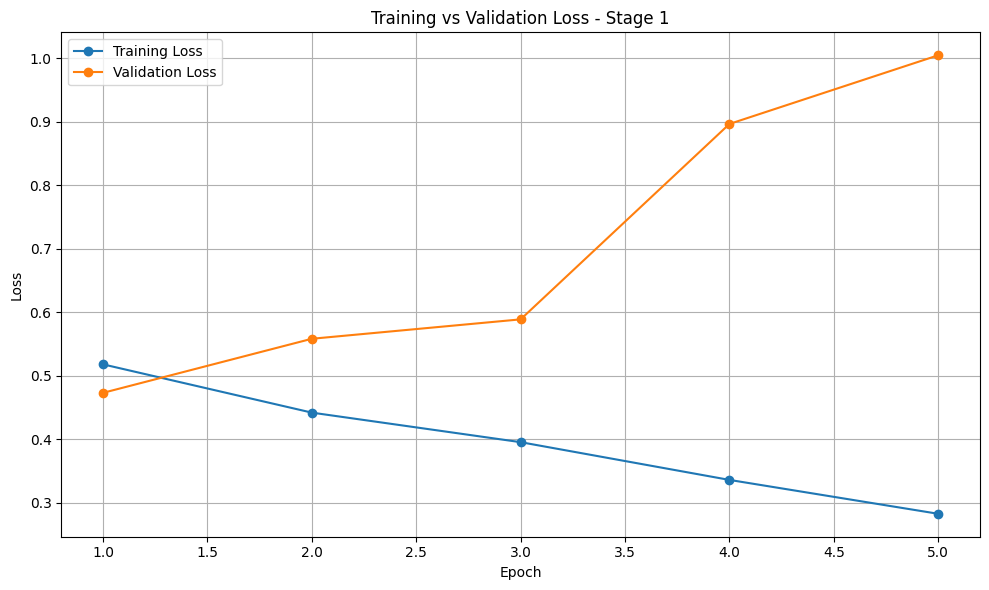

In [35]:
import matplotlib.pyplot as plt
import numpy as np

history_s1 = trainer_s1.state.log_history

# =========================
# Training Loss
# =========================

train_logs_s1 = [
    x for x in history_s1
    if 'loss' in x and 'eval_loss' not in x
]

train_epochs_s1 = [x['epoch'] for x in train_logs_s1]
train_losses_s1 = [x['loss'] for x in train_logs_s1]

# Kelompokkan training loss berdasarkan epoch
epoch_numbers_s1 = sorted(
    set(int(np.ceil(e)) for e in train_epochs_s1)
)

avg_train_loss_s1 = []

for epoch in epoch_numbers_s1:
    losses = [
        loss
        for e, loss in zip(train_epochs_s1, train_losses_s1)
        if int(np.ceil(e)) == epoch
    ]

    avg_train_loss_s1.append(np.mean(losses))


# =========================
# Validation Loss
# =========================

val_logs_s1 = [
    x for x in history_s1
    if 'eval_loss' in x
]

# Ambil validation loss PERTAMA untuk setiap epoch
val_loss_by_epoch_s1 = {}

for x in val_logs_s1:
    epoch = int(round(x['epoch']))

    if epoch not in val_loss_by_epoch_s1:
        val_loss_by_epoch_s1[epoch] = x['eval_loss']

val_epochs_s1 = sorted(val_loss_by_epoch_s1.keys())

val_losses_s1 = [
    val_loss_by_epoch_s1[epoch]
    for epoch in val_epochs_s1
]

plt.figure(figsize=(10, 6))

plt.plot(epoch_numbers_s1, avg_train_loss_s1, marker='o', label='Training Loss')
plt.plot(val_epochs_s1, val_losses_s1, marker='o', label='Validation Loss')
plt.title('Training vs Validation Loss - Stage 1')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

In [36]:
evaluation_results1 = trainer_s1.evaluate()
print(evaluation_results1)

{'eval_loss': 0.5923651456832886, 'eval_accuracy': 0.875284306292646, 'eval_f1': 0.4930662557781202, 'eval_recall': 0.6666666666666666, 'eval_precision': 0.39119804400978, 'eval_roc_auc': 0.7814150681123158, 'eval_runtime': 14.3418, 'eval_samples_per_second': 183.938, 'eval_steps_per_second': 11.505, 'epoch': 5.0}


In [37]:
# Tune the Stage 1 decision threshold on the VALIDATION set (never the test set), to
# avoid the leakage of choosing a threshold on the exact data we then report metrics on.
# Reuses the checkpoint already trained above -- no retraining. Sweeps the toxic-class
# (label 1) probability against a precision-recall curve and picks the threshold that
# maximizes F1 on validation.
from sklearn.metrics import precision_recall_curve

pred1_val = trainer_s1.predict(val_dataset_1)
probs1_val = torch.softmax(torch.tensor(pred1_val.predictions), dim=-1)[:, 1].numpy()
y_val_numeric = y_val

precision_curve_s1, recall_curve_s1, thresholds_s1 = precision_recall_curve(y_val_numeric, probs1_val)
f1_curve_s1 = (
    2 * precision_curve_s1 * recall_curve_s1
    / (precision_curve_s1 + recall_curve_s1 + 1e-12)
)
# precision/recall have one more point than thresholds (the last point has no threshold)
best_idx_s1 = np.argmax(f1_curve_s1[:-1])
best_threshold_s1 = thresholds_s1[best_idx_s1]

print(f"Stage 1 best threshold (max F1 on validation): {best_threshold_s1:.4f}")
print(
    f"  validation precision={precision_curve_s1[best_idx_s1]:.4f} "
    f"recall={recall_curve_s1[best_idx_s1]:.4f} "
    f"f1={f1_curve_s1[best_idx_s1]:.4f}"
)

Stage 1 best threshold (max F1 on validation): 0.9314
  validation precision=0.5242 recall=0.4958 f1=0.5096


In [38]:
# Final, one-shot evaluation on the untouched TEST set -- scored at both the default
# 0.5 cutoff and the threshold tuned above on validation. This is the number that
# should actually get reported.
pred1 = trainer_s1.predict(test_dataset_1)
pred_label1 = pred1.predictions.argmax(axis=1)

y_test_numeric = y_test

probs1_test = torch.softmax(torch.tensor(pred1.predictions), dim=-1)[:, 1].numpy()
pred_label1_tuned = (probs1_test >= best_threshold_s1).astype(int)

print("Stage 1 classification report @ default threshold (0.5) -- test set:")
print(classification_report(y_test_numeric, pred_label1))

print(f"\nStage 1 classification report @ threshold tuned on validation ({best_threshold_s1:.4f}) -- test set:")
print(classification_report(y_test_numeric, pred_label1_tuned))

Stage 1 classification report @ default threshold (0.5) -- test set:
              precision    recall  f1-score   support

           0       0.96      0.89      0.93      4796
           1       0.37      0.65      0.48       480

    accuracy                           0.87      5276
   macro avg       0.67      0.77      0.70      5276
weighted avg       0.91      0.87      0.88      5276


Stage 1 classification report @ threshold tuned on validation (0.9314) -- test set:
              precision    recall  f1-score   support

           0       0.95      0.95      0.95      4796
           1       0.51      0.48      0.49       480

    accuracy                           0.91      5276
   macro avg       0.73      0.72      0.72      5276
weighted avg       0.91      0.91      0.91      5276



# stage 2

In [39]:
df_toxic = df_main[df_main["toxicity"] == 1].copy()

In [40]:
LABEL_COLS = [
    "insults",
    "identity_attack",
    "threat_incitement_to_violence",
    "profanity_obscenity",
    "sexually_explicit"
]

X = df_toxic["processed_text"]
y2 = df_toxic[LABEL_COLS]

In [41]:
# Split into train / validation / test (70% / 20% / 10%). The test split uses the same
# test_size=0.2, random_state=42 as before, so it is the exact same held-out data as
# earlier runs -- only the remaining 80% is further split into train/validation. Just
# like Stage 1: validation drives checkpoint selection and threshold tuning, test is
# scored once, untouched, at the very end.
train_val_df_s2, test_df_s2 = train_test_split(
    df_toxic, test_size=0.2, random_state=42
)
train_df_s2, val_df_s2 = train_test_split(
    train_val_df_s2, test_size=0.125, random_state=42
)

train_df_s2 = train_df_s2[["processed_text"] + LABEL_COLS].copy()
val_df_s2 = val_df_s2[["processed_text"] + LABEL_COLS].copy()
test_df_s2 = test_df_s2[["processed_text"] + LABEL_COLS].copy()

print("Stage 2 split sizes:", {"train": len(train_df_s2), "val": len(val_df_s2), "test": len(test_df_s2)})

Stage 2 split sizes: {'train': 1679, 'val': 240, 'test': 480}


In [42]:
# Handle imbalance for Stage 2 (multi-label) via random oversampling of minority-label rows.
# For each label whose positive count is below the most frequent label's count, duplicate
# (with replacement) rows that carry that label until the gap is filled. Only the training
# split is resampled -- val_df_s2 and test_df_s2 keep the original distribution.
def oversample_multilabel(df, label_cols, random_state=42):
    max_count = df[label_cols].sum().max()
    parts = [df]
    for col in label_cols:
        col_count = df[col].sum()
        n_needed = int(max_count - col_count)
        if n_needed > 0:
            minority_rows = df[df[col] == 1]
            if len(minority_rows) > 0:
                parts.append(minority_rows.sample(n=n_needed, replace=True, random_state=random_state))
    balanced = pd.concat(parts).sample(frac=1, random_state=random_state).reset_index(drop=True)
    return balanced

print("Before oversampling:", {c: int(train_df_s2[c].sum()) for c in LABEL_COLS})

train_df_s2 = oversample_multilabel(train_df_s2, LABEL_COLS, random_state=42)

print("After oversampling:", {c: int(train_df_s2[c].sum()) for c in LABEL_COLS})

Before oversampling: {'insults': 729, 'identity_attack': 698, 'threat_incitement_to_violence': 78, 'profanity_obscenity': 258, 'sexually_explicit': 47}
After oversampling: {'insults': 1028, 'identity_attack': 1161, 'threat_incitement_to_violence': 740, 'profanity_obscenity': 977, 'sexually_explicit': 744}


In [43]:
train_df_s2["label"] = train_df_s2[LABEL_COLS].astype(float).values.tolist()
val_df_s2["label"] = val_df_s2[LABEL_COLS].astype(float).values.tolist()
test_df_s2["label"] = test_df_s2[LABEL_COLS].astype(float).values.tolist()

train_df_s2 = train_df_s2[["processed_text", "label"]]
val_df_s2 = val_df_s2[["processed_text", "label"]]
test_df_s2 = test_df_s2[["processed_text", "label"]]

In [44]:
dataset_s2 = DatasetDict({
    "train": Dataset.from_pandas(train_df_s2.reset_index(drop=True)),
    "validation": Dataset.from_pandas(val_df_s2.reset_index(drop=True)),
    "test": Dataset.from_pandas(test_df_s2.reset_index(drop=True))
})

In [45]:
MODEL_NAME = "indolem/indobertweet-base-uncased"

tokenizer_s2 = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

In [46]:
def tokenize_s2(batch):
    return tokenizer_s2(
        batch["processed_text"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

tokenized_datasets_2 = dataset_s2.map(
    tokenize_s2,
    batched=True
)

tokenized_datasets_2 = tokenized_datasets_2.remove_columns(
    ["processed_text"]
)

tokenized_datasets_2 = tokenized_datasets_2.rename_column(
    "label",
    "labels"
)

tokenized_datasets_2.set_format("torch")
train_dataset_2 = tokenized_datasets_2["train"]
val_dataset_2 = tokenized_datasets_2["validation"]
test_dataset_2 = tokenized_datasets_2["test"]

Map:   0%|          | 0/3514 [00:00<?, ? examples/s]

Map:   0%|          | 0/240 [00:00<?, ? examples/s]

Map:   0%|          | 0/480 [00:00<?, ? examples/s]

In [47]:
model_s2 = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(LABEL_COLS),
    problem_type="multi_label_classification"
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

In [48]:
import numpy as np
from sklearn.metrics import f1_score, roc_auc_score


def compute_metrics_s2(eval_pred):
    logits, labels = eval_pred


    preds = (logits > 0).astype(int)

    return {
        "f1_micro": f1_score(labels, preds, average="micro"),
        "f1_macro": f1_score(labels, preds, average="macro"),
        "accuracy": accuracy_score(labels, preds),
        "recall_micro": recall_score(
            labels,
            preds,
            average="micro",
            zero_division=0
        ),

        "precision_micro": precision_score(
            labels,
            preds,
            average="micro",
            zero_division=0
        )

    }

In [ ]:
# metric_for_best_model="f1_macro" (with greater_is_better=True) instead of the default
# eval_loss: compute_metrics_s2 doesn't expose a plain "f1" key, so we pick f1_macro
# specifically -- it averages F1 across all 5 labels UNWEIGHTED, so rare labels like
# threat_incitement_to_violence / sexually_explicit pull the selection metric just as
# much as the frequent ones instead of being drowned out. eval_dataset is the
# VALIDATION split (not test), so checkpoint selection never looks at the test set.
#
# weight_decay=0.01 regularizes the weights (via AdamW) to reduce overfitting, same
# reasoning as Stage 1. EarlyStoppingCallback stops training once eval_f1_macro hasn't
# improved for early_stopping_patience consecutive eval rounds, instead of always
# running the full num_train_epochs.
args_s2 = TrainingArguments(
    output_dir="./baseline_s2",
    num_train_epochs=5,
    logging_steps=1,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    learning_rate = 1e-5,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    greater_is_better=True,
    disable_tqdm=False
)

trainer_s2 = Trainer(
    model=model_s2,
    args=args_s2,
    train_dataset=train_dataset_2,
    eval_dataset=val_dataset_2,
    compute_metrics=compute_metrics_s2,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)]
)

In [50]:
trainer_s2.train()

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,F1 Micro,F1 Macro,Accuracy,Recall Micro,Precision Micro
1,0.593375,0.813169,0.369792,0.405674,0.241667,0.278431,0.550388
2,0.522754,0.753521,0.471111,0.441021,0.279167,0.415686,0.543590
3,0.366301,0.756289,0.563810,0.497748,0.312500,0.580392,0.548148
4,0.422613,0.752414,0.564972,0.497815,0.304167,0.588235,0.543478
5,0.470931,0.746640,0.572519,0.509933,0.333333,0.588235,0.557621


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1100, training_loss=0.5646625544808128, metrics={'train_runtime': 328.4394, 'train_samples_per_second': 53.495, 'train_steps_per_second': 3.349, 'total_flos': 1155746440773120.0, 'train_loss': 0.5646625544808128, 'epoch': 5.0})

In [ ]:
import json, os

# Persist the best checkpoint (already loaded into trainer_s2.model because
# load_best_model_at_end=True) + tokenizer, and the full training log, so both can be
# reloaded later without rerunning trainer_s2.train().
SAVE_DIR_S2 = "./best_model_s2"
os.makedirs(SAVE_DIR_S2, exist_ok=True)

trainer_s2.save_model(SAVE_DIR_S2)
tokenizer_s2.save_pretrained(SAVE_DIR_S2)

with open(os.path.join(SAVE_DIR_S2, "log_history.json"), "w") as f:
    json.dump(trainer_s2.state.log_history, f)

print(f"Saved best model + tokenizer + log_history to {SAVE_DIR_S2}")

# --- To reload later (e.g. new session, without retraining) ---
# model_s2 = AutoModelForSequenceClassification.from_pretrained(
#     SAVE_DIR_S2, num_labels=len(LABEL_COLS), problem_type="multi_label_classification"
# )
# tokenizer_s2 = AutoTokenizer.from_pretrained(SAVE_DIR_S2)
# with open(os.path.join(SAVE_DIR_S2, "log_history.json")) as f:
#     history_s2 = json.load(f)

In [51]:
history_s2 = trainer_s2.state.log_history
train_loss_s2 = [x['loss'] for x in history_s2 if 'loss' in x]
val_loss_s2 = [x['eval_loss'] for x in history_s2 if 'eval_loss' in x]
epochs_s2 = [x['epoch'] for x in history_s2 if 'eval_loss' in x]

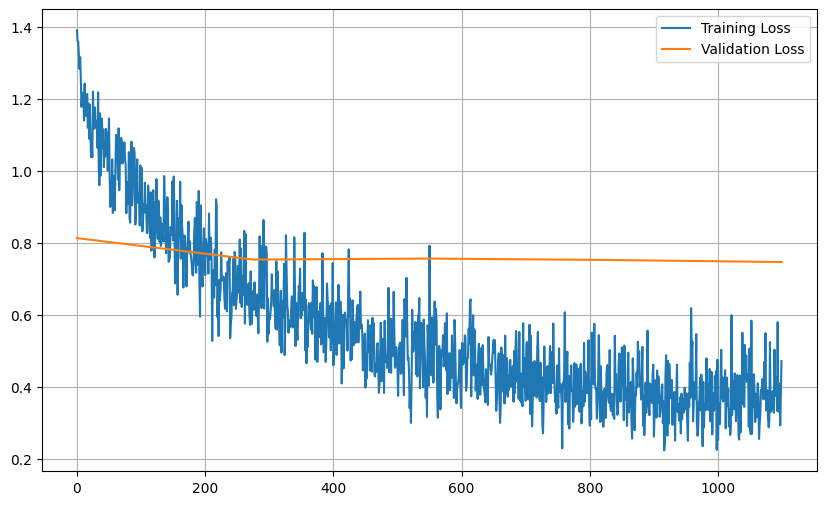

In [52]:
plt.figure(figsize=(10, 6))

plt.plot(train_loss_s2, label='Training Loss')

plt.plot(
    np.linspace(0, len(train_loss_s2)-1, len(val_loss_s2)),
    val_loss_s2,
    label='Validation Loss'
)

plt.legend()
plt.grid(True)
plt.show()

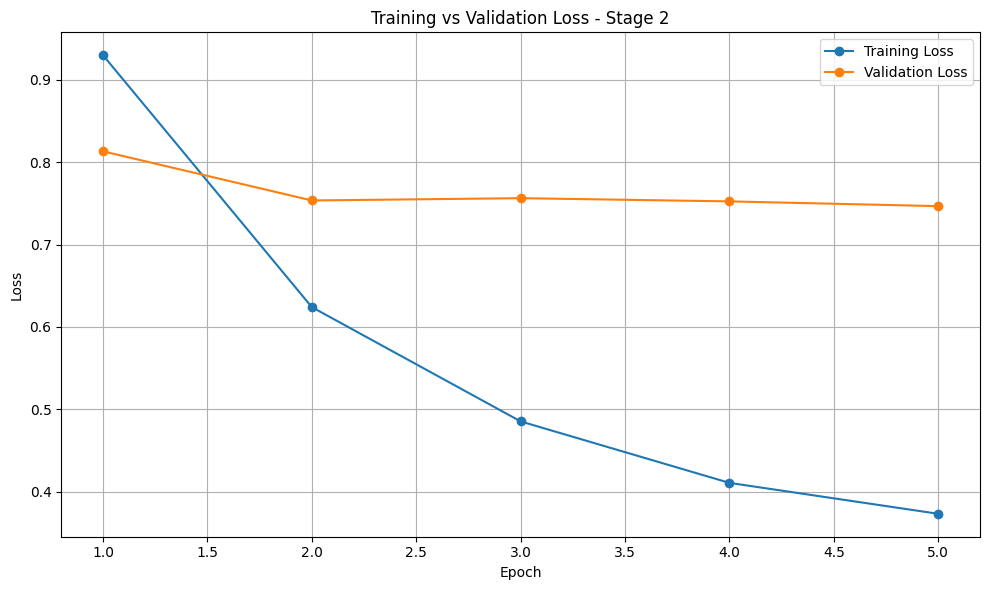

In [53]:
import matplotlib.pyplot as plt
import numpy as np

history_s2 = trainer_s2.state.log_history

# =========================
# Training Loss
# =========================

train_logs_s2 = [
    x for x in history_s2
    if 'loss' in x and 'eval_loss' not in x
]

train_epochs_s2 = [x['epoch'] for x in train_logs_s2]
train_losses_s2 = [x['loss'] for x in train_logs_s2]

# Kelompokkan training loss berdasarkan epoch
epoch_numbers_s2 = sorted(
    set(int(np.ceil(e)) for e in train_epochs_s2)
)

avg_train_loss_s2 = []

for epoch in epoch_numbers_s2:
    losses = [
        loss
        for e, loss in zip(train_epochs_s2, train_losses_s2)
        if int(np.ceil(e)) == epoch
    ]

    avg_train_loss_s2.append(np.mean(losses))


# =========================
# Validation Loss
# =========================

val_logs_s2 = [
    x for x in history_s2
    if 'eval_loss' in x
]

# Ambil validation loss PERTAMA untuk setiap epoch
val_loss_by_epoch_s2 = {}

for x in val_logs_s2:
    epoch = int(round(x['epoch']))

    if epoch not in val_loss_by_epoch_s2:
        val_loss_by_epoch_s2[epoch] = x['eval_loss']

val_epochs_s2 = sorted(val_loss_by_epoch_s2.keys())

val_losses_s2 = [
    val_loss_by_epoch_s2[epoch]
    for epoch in val_epochs_s2
]

plt.figure(figsize=(10, 6))
plt.plot( epoch_numbers_s2, avg_train_loss_s2, marker='o', label='Training Loss')
plt.plot(val_epochs_s2, val_losses_s2, marker='o', label='Validation Loss')
plt.title('Training vs Validation Loss - Stage 2')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

In [54]:
evaluation_results2 = trainer_s2.evaluate()
print(evaluation_results2)

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


{'eval_loss': 0.7466396689414978, 'eval_f1_micro': 0.5725190839694656, 'eval_f1_macro': 0.5099328957669006, 'eval_accuracy': 0.3333333333333333, 'eval_recall_micro': 0.5882352941176471, 'eval_precision_micro': 0.5576208178438662, 'eval_runtime': 1.4352, 'eval_samples_per_second': 167.222, 'eval_steps_per_second': 10.451, 'epoch': 5.0}


In [55]:
# Tune a separate decision threshold per label on the VALIDATION set (never the test
# set), reusing the checkpoint already trained above -- no retraining. A single global
# 0.5 threshold is exactly what causes rare labels like threat_incitement_to_violence to
# collapse: at 0.5 the model rarely emits a confident-enough positive for a label it has
# seen so few of, so precision/recall both tank. Sweeping per label lets each one use
# whatever cutoff actually maximizes its own F1 -- tuned on validation only.
from sklearn.metrics import precision_recall_curve

pred2_val = trainer_s2.predict(val_dataset_2)
logits_val = pred2_val.predictions
probs_val = 1 / (1 + np.exp(-logits_val))
y_val_true = pred2_val.label_ids

best_thresholds_s2 = {}

for i, label_name in enumerate(LABEL_COLS):
    precision_curve, recall_curve, thresholds_curve = precision_recall_curve(
        y_val_true[:, i], probs_val[:, i]
    )
    f1_curve = 2 * precision_curve * recall_curve / (precision_curve + recall_curve + 1e-12)
    best_idx = np.argmax(f1_curve[:-1])
    best_thresholds_s2[label_name] = float(thresholds_curve[best_idx])

    print(
        f"{label_name}: best threshold (val)={thresholds_curve[best_idx]:.4f} "
        f"precision={precision_curve[best_idx]:.4f} "
        f"recall={recall_curve[best_idx]:.4f} "
        f"f1={f1_curve[best_idx]:.4f}"
    )

threshold_vector_s2 = np.array([best_thresholds_s2[c] for c in LABEL_COLS])

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


insults: best threshold (val)=0.2393 precision=0.5531 recall=0.9167 f1=0.6899
identity_attack: best threshold (val)=0.2914 precision=0.4800 recall=0.8660 f1=0.6176
threat_incitement_to_violence: best threshold (val)=0.5203 precision=0.3333 recall=0.4545 f1=0.3846
profanity_obscenity: best threshold (val)=0.1641 precision=0.5085 recall=0.8333 f1=0.6316
sexually_explicit: best threshold (val)=0.2471 precision=0.5000 recall=0.6667 f1=0.5714


In [56]:
# Final, one-shot evaluation on the untouched TEST set -- scored at both the default
# 0.5 cutoff and the per-label thresholds tuned above on validation. This is the number
# that should actually get reported.
pred2 = trainer_s2.predict(test_dataset_2)
logits = pred2.predictions

probs = 1 / (1 + np.exp(-logits))

threshold = 0.5
pred_label2 = (probs > threshold).astype(int)
pred_label2_tuned = (probs >= threshold_vector_s2).astype(int)

y_true = pred2.label_ids

print("Stage 2 classification report @ default threshold (0.5) -- test set:")
print(classification_report(y_true, pred_label2, target_names=LABEL_COLS))

print("\nStage 2 classification report @ per-label thresholds tuned on validation -- test set:")
print(classification_report(y_true, pred_label2_tuned, target_names=LABEL_COLS))

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Stage 2 classification report @ default threshold (0.5) -- test set:
                               precision    recall  f1-score   support

                      insults       0.66      0.55      0.60       218
              identity_attack       0.58      0.66      0.62       199
threat_incitement_to_violence       0.21      0.32      0.25        19
          profanity_obscenity       0.61      0.58      0.60        65
            sexually_explicit       0.67      0.55      0.60        11

                    micro avg       0.59      0.59      0.59       512
                    macro avg       0.55      0.53      0.53       512
                 weighted avg       0.61      0.59      0.59       512
                  samples avg       0.50      0.51      0.49       512


Stage 2 classification report @ per-label thresholds tuned on validation -- test set:
                               precision    recall  f1-score   support

                      insults       0.56      0.84      0.6

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in samples with no true labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in samples with no true nor predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/me

In [57]:
for i, label_name in enumerate(LABEL_COLS):

    print(f"\n===== {label_name} (default threshold=0.5) =====")

    print(
        classification_report(
            y_true[:, i],
            pred_label2[:, i]
        )
    )


===== insults (default threshold=0.5) =====
              precision    recall  f1-score   support

         0.0       0.67      0.77      0.72       262
         1.0       0.66      0.55      0.60       218

    accuracy                           0.67       480
   macro avg       0.67      0.66      0.66       480
weighted avg       0.67      0.67      0.66       480


===== identity_attack (default threshold=0.5) =====
              precision    recall  f1-score   support

         0.0       0.74      0.66      0.70       281
         1.0       0.58      0.66      0.62       199

    accuracy                           0.66       480
   macro avg       0.66      0.66      0.66       480
weighted avg       0.67      0.66      0.66       480


===== threat_incitement_to_violence (default threshold=0.5) =====
              precision    recall  f1-score   support

         0.0       0.97      0.95      0.96       461
         1.0       0.21      0.32      0.25        19

    accuracy     

In [58]:
for i, label_name in enumerate(LABEL_COLS):

    print(f"\n===== {label_name} (tuned threshold={best_thresholds_s2[label_name]:.4f}) =====")

    print(
        classification_report(
            y_true[:, i],
            pred_label2_tuned[:, i]
        )
    )


===== insults (tuned threshold=0.2393) =====
              precision    recall  f1-score   support

         0.0       0.78      0.45      0.57       262
         1.0       0.56      0.84      0.67       218

    accuracy                           0.63       480
   macro avg       0.67      0.65      0.62       480
weighted avg       0.68      0.63      0.62       480


===== identity_attack (tuned threshold=0.2914) =====
              precision    recall  f1-score   support

         0.0       0.80      0.40      0.53       281
         1.0       0.50      0.86      0.64       199

    accuracy                           0.59       480
   macro avg       0.65      0.63      0.58       480
weighted avg       0.68      0.59      0.57       480


===== threat_incitement_to_violence (tuned threshold=0.5203) =====
              precision    recall  f1-score   support

         0.0       0.97      0.96      0.96       461
         1.0       0.23      0.32      0.27        19

    accuracy  